In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import surprise
from surprise import accuracy


In [2]:
dataset_path = Path('../dataset')
train_df = pd.read_csv(dataset_path / 'train.csv')
train_df.date = pd.to_datetime(train_df.date)

test_df = pd.read_csv(dataset_path / 'validation.csv')
test_df.date = pd.to_datetime(test_df.date)

In [3]:
reader = surprise.reader.Reader(rating_scale=(0,5))

train_data = surprise.Dataset.load_from_df(
    train_df[["user_id", "recipe_id", "rating"]], reader=reader
)
trainset = train_data.build_full_trainset()

test_data = surprise.Dataset.load_from_df(
    test_df[["user_id", "recipe_id", "rating"]], reader=reader
)
testset = test_data.construct_testset(
    test_data.raw_ratings
)


In [4]:
k_values = [5, 10, 30, 50, 70, 100]
mae_values = []
rmse_values = []

for k in k_values:
  model = surprise.KNNBasic(k=k, sim_options={'name': 'pearson', 'user_based': False})
  model.fit(trainset)
  predictions = model.test(testset)
  rmse_values.append(accuracy.rmse(predictions))
  mae_values.append(accuracy.mae(predictions))

Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 1.0009
MAE:  0.5392
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 0.9974
MAE:  0.5388
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 0.9969
MAE:  0.5390
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 0.9969
MAE:  0.5390
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 0.9969
MAE:  0.5390
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 0.9969
MAE:  0.5390


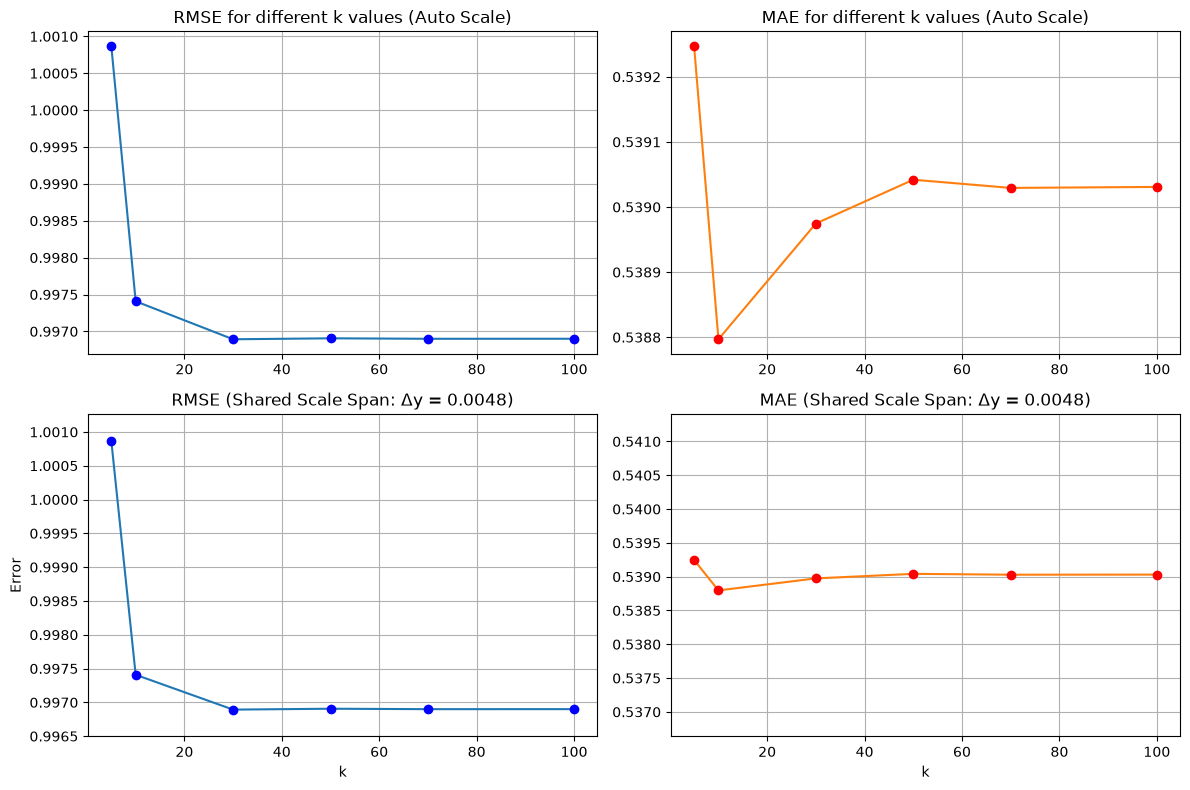

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

# Top row: original auto scale
rmse_ax_top, mae_ax_top = axs[0, 0], axs[0, 1]

rmse_ax_top.plot(k_values, rmse_values, color="tab:blue")
rmse_ax_top.plot(k_values, rmse_values, "bo")
rmse_ax_top.grid(True)
rmse_ax_top.set_title("RMSE for different k values (Auto Scale)")

# Changed MAE top line and marker colors to orange / red
mae_ax_top.plot(k_values, mae_values, color="tab:orange")
mae_ax_top.plot(k_values, mae_values, "ro")
mae_ax_top.grid(True)
mae_ax_top.set_title("MAE for different k values (Auto Scale)")

# Bottom row: matching scale height and tick spacing
rmse_ax_bot, mae_ax_bot = axs[1, 0], axs[1, 1]

# 1. Determine common range span (delta) and tick interval
rmse_span = np.ptp(rmse_values)
mae_span = np.ptp(mae_values)
shared_span = max(rmse_span, mae_span) * 1.2  # Add 20% padding
tick_step = 0.0005  # Uniform tick line separation for both

# Center limits around each metric's midpoint
rmse_mid = (np.max(rmse_values) + np.min(rmse_values)) / 2
mae_mid = (np.max(mae_values) + np.min(mae_values)) / 2

rmse_ax_bot.set_ylim(rmse_mid - shared_span / 2, rmse_mid + shared_span / 2)
mae_ax_bot.set_ylim(mae_mid - shared_span / 2, mae_mid + shared_span / 2)

# Apply identical tick distance
rmse_ax_bot.yaxis.set_major_locator(ticker.MultipleLocator(tick_step))
mae_ax_bot.yaxis.set_major_locator(ticker.MultipleLocator(tick_step))

# 2. Plot bottom series
rmse_ax_bot.plot(k_values, rmse_values, color="tab:blue")
rmse_ax_bot.plot(k_values, rmse_values, "bo")
rmse_ax_bot.grid(True)
rmse_ax_bot.set_title(f"RMSE (Shared Scale Span: Δy = {shared_span:.4f})")
rmse_ax_bot.set_xlabel("k")
rmse_ax_bot.set_ylabel("Error")

mae_ax_bot.plot(k_values, mae_values, color="tab:orange")
mae_ax_bot.plot(k_values, mae_values, "ro")
mae_ax_bot.grid(True)
mae_ax_bot.set_title(f"MAE (Shared Scale Span: Δy = {shared_span:.4f})")
mae_ax_bot.set_xlabel("k")

plt.tight_layout()
plt.show()

## Best k for item knn = 20

In [17]:
from tarea_01.utils import calculate_metrics

best_k = 20

model = surprise.KNNBasic(k=best_k, sim_options={'name': 'pearson', 'user_based': False})
model.fit(trainset)

metrics = calculate_metrics(
    model=model,
    testset=testset,
    k=10,
    threshold=4.0,
)

metrics

Computing the pearson similarity matrix...
Done computing similarity matrix.


{'RMSE': 0.997,
 'Recall@10': 0.9455,
 'Precision@10': 0.9396,
 'NDCG@10': 0.972,
 'MAP@10': 0.9556,
 'Diversity': 0.841,
 'Novelty': 11.9041}